# Phase 2: MLP baseline (PyTorch)

**Task:** predict a product's **group** (9 classes) from its 32×32 RGB photo, flattened to 3,072 numbers.
**Why:** this "no convolution" network is the baseline the Phase 3 CNN has to beat.
**Rule:** only train and val are used here. Test stays untouched until the final evaluation.

## 1. Load the data

In [1]:
import numpy as np

d = np.load("../data/processed/mlp_32x32.npz")

X_train = d["X_train"].astype(np.float32) / 255.0   # pixels 0-255 -> 0-1
X_val   = d["X_val"].astype(np.float32) / 255.0
y_train = d["y_group_train"]
y_val   = d["y_group_val"]
classes = list(d["group_classes"])

print("Train:", X_train.shape, "| Val:", X_val.shape)
print("Products per class:", dict(zip(classes, np.bincount(y_train))))
majority_acc = (y_val == np.bincount(y_train).argmax()).mean()
print(f"Majority-class baseline (always guess the biggest class): val acc {majority_acc:.3f}")

Train: (74295, 3072) | Val: (14859, 3072)
Products per class: {np.str_('Accessories'): np.int64(7825), np.str_('Garment Full body'): np.int64(9401), np.str_('Garment Lower body'): np.int64(13973), np.str_('Garment Upper body'): np.int64(30234), np.str_('Nightwear'): np.int64(1352), np.str_('Shoes'): np.int64(3679), np.str_('Socks & Tights'): np.int64(1730), np.str_('Swimwear'): np.int64(2221), np.str_('Underwear'): np.int64(3880)}
Majority-class baseline (always guess the biggest class): val acc 0.407


## 2. Standardize the inputs
Centre every input around 0 with spread 1, using **train-only** statistics (no leakage into val).
Without this, the inputs are all positive and mostly near 1 (white background), which makes training zig-zag.

In [2]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0) + 1e-6          # + tiny number avoids dividing by 0
X_train_s = (X_train - mean) / std
X_val_s = (X_val - mean) / std             # val uses TRAIN's mean/std
print("After standardizing:", X_train_s.mean().round(3), X_train_s.std().round(3))   # ~0 and ~1

After standardizing: -0.001 0.999


## 3. Define the network: 3,072 → 256 → 128 → 9

In [3]:
import torch
from torch import nn

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

model = nn.Sequential(
    nn.Linear(3072, 256), nn.ReLU(),
    nn.Linear(256, 128),  nn.ReLU(),
    nn.Linear(128, 9),
).to(device)

print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))   # expect 820745

Using: cuda
Sequential(
  (0): Linear(in_features=3072, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=9, bias=True)
)
Parameters: 820745


## 4. Train (early stopping on val loss)
Each batch: forward → loss → backward → update. After each epoch, check train and val.
Keep the weights from the epoch with the lowest **val** loss; stop if val hasn't improved for `patience` epochs.

In [4]:
import copy

X_tr = torch.tensor(X_train_s, device=device)
y_tr = torch.tensor(y_train, device=device)
X_va = torch.tensor(X_val_s, device=device)
y_va = torch.tensor(y_val, device=device)

loss_fn = nn.CrossEntropyLoss()                                        # softmax + cross-entropy
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

batch_size = 256
epochs = 60
patience = 8
history = []
best_val_loss = float("inf")
bad_epochs = 0

for epoch in range(1, epochs + 1):
    model.train()
    order = torch.randperm(len(X_tr), device=device)     # shuffle every epoch
    for i in range(0, len(X_tr), batch_size):
        idx = order[i:i + batch_size]
        logits = model(X_tr[idx])            # 1. forward pass
        loss = loss_fn(logits, y_tr[idx])    # 2. loss
        optimizer.zero_grad()                # 3. clear old gradients
        loss.backward()                      # 4. backward pass
        optimizer.step()                     # 5. update weights

    model.eval()
    with torch.no_grad():
        train_loss = loss_fn(model(X_tr), y_tr).item()
        val_logits = model(X_va)
        val_loss = loss_fn(val_logits, y_va).item()
        val_acc = (val_logits.argmax(dim=1) == y_va).float().mean().item()
    history.append((epoch, train_loss, val_loss, val_acc))
    print(f"epoch {epoch:2d} | train loss {train_loss:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f}")

    if val_loss < best_val_loss:
        best_val_loss, best_epoch, bad_epochs = val_loss, epoch, 0
        best_state = copy.deepcopy(model.state_dict())
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"No improvement for {patience} epochs, stopping.")
            break

model.load_state_dict(best_state)
print(f"\nBest epoch: {best_epoch} (val loss {best_val_loss:.3f})")

epoch  1 | train loss 0.821 | val loss 0.835 | val acc 0.728
epoch  2 | train loss 0.767 | val loss 0.804 | val acc 0.738
epoch  3 | train loss 0.668 | val loss 0.712 | val acc 0.764
epoch  4 | train loss 0.552 | val loss 0.625 | val acc 0.798
epoch  5 | train loss 0.524 | val loss 0.618 | val acc 0.803
epoch  6 | train loss 0.484 | val loss 0.585 | val acc 0.814
epoch  7 | train loss 0.454 | val loss 0.571 | val acc 0.825
epoch  8 | train loss 0.471 | val loss 0.600 | val acc 0.814
epoch  9 | train loss 0.409 | val loss 0.553 | val acc 0.831
epoch 10 | train loss 0.385 | val loss 0.547 | val acc 0.834
epoch 11 | train loss 0.399 | val loss 0.568 | val acc 0.826
epoch 12 | train loss 0.414 | val loss 0.606 | val acc 0.813
epoch 13 | train loss 0.404 | val loss 0.598 | val acc 0.822
epoch 14 | train loss 0.356 | val loss 0.577 | val acc 0.829
epoch 15 | train loss 0.328 | val loss 0.551 | val acc 0.836
epoch 16 | train loss 0.338 | val loss 0.571 | val acc 0.838
epoch 17 | train loss 0.

## 5. Learning curves

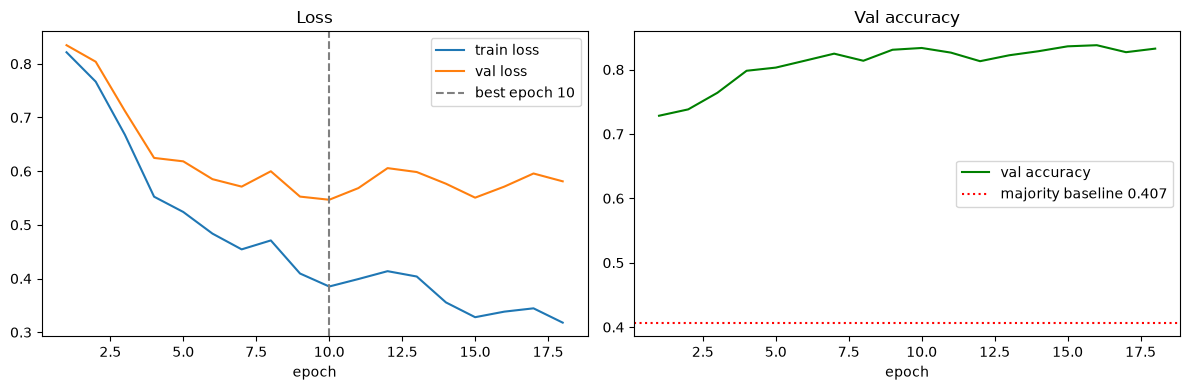

In [5]:
import matplotlib.pyplot as plt

ep = [h[0] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, [h[1] for h in history], label="train loss")
ax[0].plot(ep, [h[2] for h in history], label="val loss")
ax[0].axvline(best_epoch, ls="--", c="grey", label=f"best epoch {best_epoch}")
ax[0].set_xlabel("epoch"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(ep, [h[3] for h in history], c="green", label="val accuracy")
ax[1].axhline(majority_acc, ls=":", c="red", label=f"majority baseline {majority_acc:.3f}")
ax[1].set_xlabel("epoch"); ax[1].set_title("Val accuracy"); ax[1].legend()
plt.tight_layout()
plt.savefig("../reports/figures/mlp_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Val results: accuracy, macro-F1, per-class scores
Accuracy alone is misleading with imbalanced classes, so we also report **macro-F1** (every class counts equally).

In [6]:
from sklearn.metrics import classification_report, f1_score

with torch.no_grad():
    val_pred = model(X_va).argmax(dim=1).cpu().numpy()

print(f"Val accuracy: {(val_pred == y_val).mean():.3f}")
print(f"Val macro-F1: {f1_score(y_val, val_pred, average='macro'):.3f}")
print()
print(classification_report(y_val, val_pred, target_names=classes, digits=3))

Val accuracy: 0.834
Val macro-F1: 0.730

                    precision    recall  f1-score   support

       Accessories      0.798     0.707     0.750      1565
 Garment Full body      0.795     0.757     0.775      1881
Garment Lower body      0.900     0.889     0.895      2795
Garment Upper body      0.851     0.938     0.892      6047
         Nightwear      0.614     0.289     0.393       270
             Shoes      0.828     0.882     0.854       735
    Socks & Tights      0.786     0.699     0.740       346
          Swimwear      0.631     0.552     0.589       444
         Underwear      0.751     0.625     0.682       776

          accuracy                          0.834     14859
         macro avg      0.773     0.704     0.730     14859
      weighted avg      0.829     0.834     0.828     14859



## 7. Save the best weights

In [7]:
from pathlib import Path

Path("../runs").mkdir(exist_ok=True)
torch.save(model.state_dict(), "../runs/mlp_group_best.pt")
print("Saved: runs/mlp_group_best.pt")

Saved: runs/mlp_group_best.pt


## 8. Same MLP, colour target (16 classes)
Same images, same split, same settings. Only the answers change: colour instead of product group.
This gives Phase 3's CNN a colour baseline too.

In [8]:
yc_train = d["y_colour_train"]
yc_val = d["y_colour_val"]
colour_classes = list(d["colour_classes"])
colour_majority = (yc_val == np.bincount(yc_train).argmax()).mean()
print(f"Colour majority baseline (always guess '{colour_classes[np.bincount(yc_train).argmax()]}'): val acc {colour_majority:.3f}")

torch.manual_seed(42)
colour_model = nn.Sequential(
    nn.Linear(3072, 256), nn.ReLU(),
    nn.Linear(256, 128),  nn.ReLU(),
    nn.Linear(128, 16),                     # 16 colours instead of 9 groups
).to(device)

yc_tr = torch.tensor(yc_train, device=device)
yc_va = torch.tensor(yc_val, device=device)
optimizer = torch.optim.SGD(colour_model.parameters(), lr=0.01, momentum=0.9)

best_val_loss, bad_epochs = float("inf"), 0
for epoch in range(1, epochs + 1):
    colour_model.train()
    order = torch.randperm(len(X_tr), device=device)
    for i in range(0, len(X_tr), batch_size):
        idx = order[i:i + batch_size]
        loss = loss_fn(colour_model(X_tr[idx]), yc_tr[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    colour_model.eval()
    with torch.no_grad():
        train_loss = loss_fn(colour_model(X_tr), yc_tr).item()
        val_logits = colour_model(X_va)
        val_loss = loss_fn(val_logits, yc_va).item()
        val_acc = (val_logits.argmax(dim=1) == yc_va).float().mean().item()
    print(f"epoch {epoch:2d} | train loss {train_loss:.3f} | val loss {val_loss:.3f} | val acc {val_acc:.3f}")

    if val_loss < best_val_loss:
        best_val_loss, colour_best_epoch, bad_epochs = val_loss, epoch, 0
        colour_best_state = copy.deepcopy(colour_model.state_dict())
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"No improvement for {patience} epochs, stopping.")
            break

colour_model.load_state_dict(colour_best_state)
print(f"\nBest epoch: {colour_best_epoch} (val loss {best_val_loss:.3f})")

Colour majority baseline (always guess 'Black'): val acc 0.212
epoch  1 | train loss 1.136 | val loss 1.165 | val acc 0.648
epoch  2 | train loss 1.006 | val loss 1.060 | val acc 0.677
epoch  3 | train loss 0.935 | val loss 1.006 | val acc 0.695
epoch  4 | train loss 0.896 | val loss 0.982 | val acc 0.701
epoch  5 | train loss 0.862 | val loss 0.957 | val acc 0.707
epoch  6 | train loss 0.862 | val loss 0.965 | val acc 0.710
epoch  7 | train loss 0.846 | val loss 0.964 | val acc 0.705
epoch  8 | train loss 0.811 | val loss 0.950 | val acc 0.707
epoch  9 | train loss 0.783 | val loss 0.934 | val acc 0.715
epoch 10 | train loss 0.757 | val loss 0.923 | val acc 0.716
epoch 11 | train loss 0.763 | val loss 0.941 | val acc 0.712
epoch 12 | train loss 0.762 | val loss 0.958 | val acc 0.707
epoch 13 | train loss 0.739 | val loss 0.951 | val acc 0.712
epoch 14 | train loss 0.717 | val loss 0.941 | val acc 0.717
epoch 15 | train loss 0.708 | val loss 0.955 | val acc 0.714
epoch 16 | train loss 

In [ ]:
with torch.no_grad():
    colour_pred = colour_model(X_va).argmax(dim=1).cpu().numpy()

print(f"Colour val accuracy: {(colour_pred == yc_val).mean():.3f}")
print(f"Colour val macro-F1: {f1_score(yc_val, colour_pred, average='macro'):.3f}")
print()
print(classification_report(yc_val, colour_pred, target_names=colour_classes, digits=3, zero_division=0))

torch.save(colour_model.state_dict(), "../runs/mlp_colour_best.pt")
print("Saved: runs/mlp_colour_best.pt")

Colour val accuracy: 0.716
Colour val macro-F1: 0.599

              precision    recall  f1-score   support

       Beige      0.566     0.550     0.558       809
       Black      0.821     0.870     0.845      3151
        Blue      0.851     0.846     0.849      2742
       Brown      0.543     0.644     0.589       334
       Green      0.676     0.514     0.584       535
        Grey      0.523     0.602     0.560      1175
 Khaki green      0.671     0.678     0.675       451
Lilac Purple      0.563     0.356     0.436       163
       Metal      0.537     0.352     0.425       307
        Mole      0.324     0.061     0.103       180
      Orange      0.504     0.416     0.456       416
        Pink      0.697     0.748     0.721      1311
         Red      0.808     0.740     0.773       847
   Turquoise      0.564     0.524     0.543       252
       White      0.634     0.696     0.663      1757
      Yellow      0.872     0.760     0.812       429

    accuracy             